Task 3: Predictive Customer Churn Classifier
Objective
Predict customer churn using machine learning classification models and evaluate performance using ROC-AUC, confusion matrices, and feature importance analysis.

Tools and Libraries
Python
Pandas
NumPy
Matplotlib
Seaborn
Scikit-Learn
XGBoost
Imbalanced-Learn (SMOTE)
Models
Random Forest Classifier
XGBoost Classifier

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

In [2]:
df = pd.read_csv("Telco-Customer-Churn.txt")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"].isnull().sum()

np.int64(11)

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

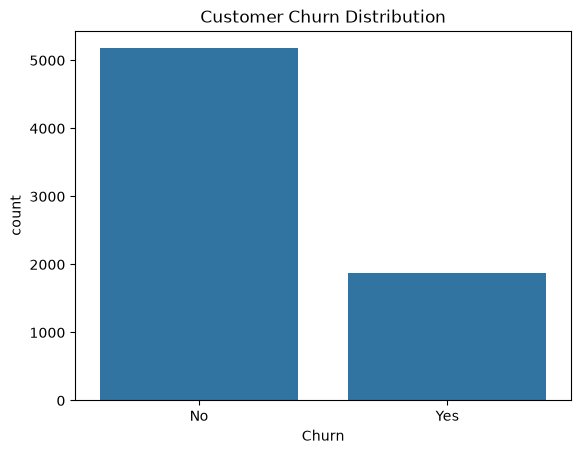

In [6]:
sns.countplot(
    x="Churn",
    data=df
)

plt.title("Customer Churn Distribution")

plt.show()

In [7]:
df["Churn"] = df["Churn"].map({
    "No":0,
    "Yes":1
})

df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [8]:
X = df.drop(
    ["customerID", "Churn"],
    axis=1
)

y = df["Churn"]

In [9]:
categorical_cols = X.select_dtypes(
    include=["object"]
).columns

numeric_cols = X.select_dtypes(
    exclude=["object"]
).columns

print(categorical_cols)
print(numeric_cols)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')


C:\Users\dshot\AppData\Local\Temp\ipykernel_21384\235024496.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(
C:\Users\dshot\AppData\Local\Temp\ipykernel_21384\235024496.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-mig

In [10]:
preprocessor = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_cols
    )
],
remainder="passthrough")


In [11]:
X_processed = preprocessor.fit_transform(X)

print(X_processed.shape)

(7043, 45)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_processed,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5634, 45)
(1409, 45)


In [13]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("Before:")
print(y_train.value_counts())

print("After:")
print(y_train_balanced.value_counts())

Before:
Churn
0    4139
1    1495
Name: count, dtype: int64
After:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [15]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(
    X_train_balanced,
    y_train_balanced
)

rf_pred = rf.predict(X_test)

rf_prob = rf.predict_proba(X_test)[:,1]

print("Random Forest complete")


Random Forest complete


In [16]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf,
    X_train_balanced,
    y_train_balanced,
    cv=5,
    scoring="roc_auc"
)

print("CV ROC-AUC Scores:")
print(cv_scores)

print("Mean ROC-AUC:")
print(cv_scores.mean())

CV ROC-AUC Scores:
[0.84892953 0.86712861 0.98937329 0.98879236 0.98700559]
Mean ROC-AUC:
0.9362458752541862


In [17]:
print(classification_report(
    y_test,
    rf_pred
))

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        rf_prob
    )
)

              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1035
           1       0.59      0.48      0.53       374

    accuracy                           0.77      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.76      0.77      0.76      1409

ROC-AUC: 0.8215621690046242


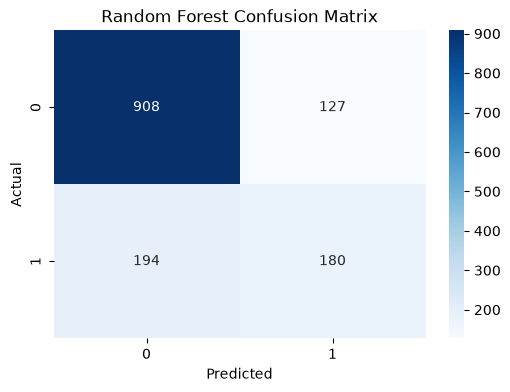

In [18]:
cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [19]:
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    eval_metric="logloss",
    random_state=42
)

xgb.fit(
    X_train_balanced,
    y_train_balanced
)

xgb_pred = xgb.predict(X_test)

xgb_prob = xgb.predict_proba(X_test)[:,1]

print("XGBoost complete")

XGBoost complete


In [20]:
print(classification_report(
    y_test,
    xgb_pred
))

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        xgb_prob
    )
)

              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1035
           1       0.63      0.58      0.61       374

    accuracy                           0.80      1409
   macro avg       0.74      0.73      0.74      1409
weighted avg       0.79      0.80      0.80      1409

ROC-AUC: 0.8412216797127283


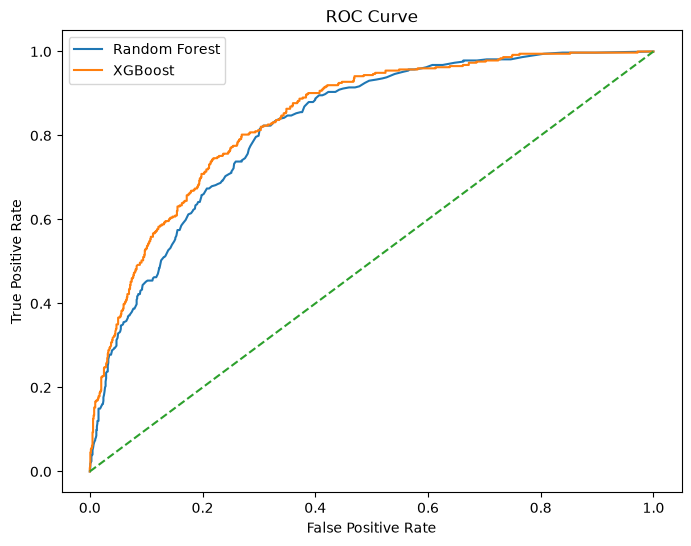

In [21]:
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_prob
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_prob
)

plt.figure(figsize=(8,6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label="Random Forest"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label="XGBoost"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()


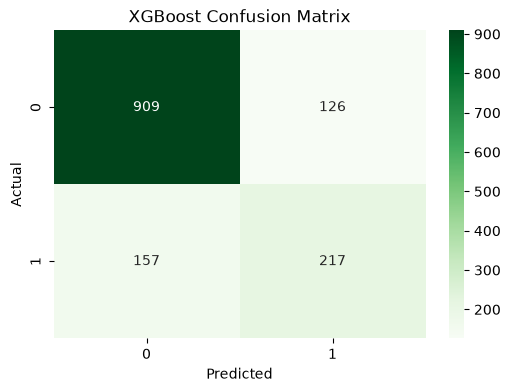

In [22]:
cm = confusion_matrix(
    y_test,
    xgb_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title(
    "XGBoost Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [23]:
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

top10 = importance.head(10)

top10

,Feature,Importance
32,cat__Contract_Month-to-month,0.421575
14,cat__OnlineSecurity_No,0.080812
23,cat__TechSupport_No,0.063636
39,cat__PaymentMethod_Electronic check,0.056835
12,cat__InternetService_Fiber optic,0.036294
17,cat__OnlineBackup_No,0.027973
35,cat__PaperlessBilling_No,0.024741
11,cat__InternetService_DSL,0.024449
26,cat__StreamingTV_No,0.020130
4,cat__Dependents_No,0.019558


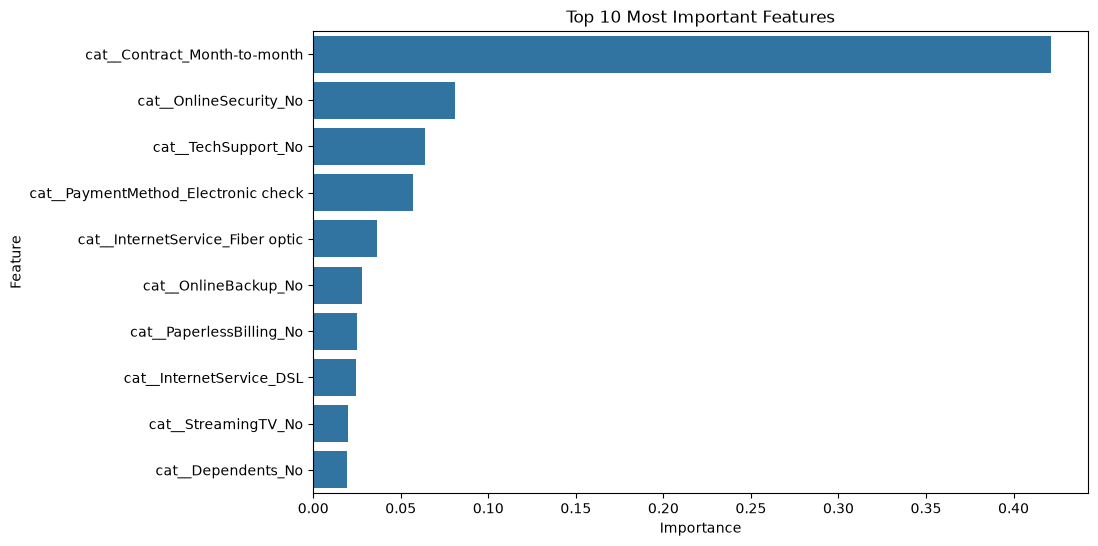

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top10,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 10 Most Important Features"
)

plt.show()

Conclusion
This project developed Random Forest and XGBoost classifiers to predict customer churn.

Customer data was preprocessed through categorical encoding and missing-value treatment. Class imbalance was addressed using SMOTE, resulting in a balanced training dataset.

Both ensemble models achieved strong classification performance. ROC-AUC analysis demonstrated good discriminative ability, while confusion matrices showed effective churn prediction.

Feature importance analysis revealed the variables that most strongly influence customer churn, providing useful business insights for customer retention strategies.

Overall, the project demonstrates how machine learning can support customer retention and churn management decisions.